# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [158]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st # importar librerías

In [159]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código
print("Archivos cargados correctamente")

Archivos cargados correctamente


In [160]:
(plans.head (5))# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [161]:
(users.head (5))# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [162]:
(usage.head (5))# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [163]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("usage", usage.shape)
print("users", users.shape)

plans (2, 8)
usage (40000, 6)
users (4000, 8)


In [164]:
plans.info ()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [165]:
users.info ()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [166]:
usage.info ()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [167]:
print(users.isnull().sum())# cantidad de nulos para users

print(users.isnull().mean())# proporción de valores nulos

print(users.isnull().mean() * 100)# proporción de valores nulos en porcentaje


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [168]:
print(usage.isnull().sum())# cantidad de nulos para usage

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

1- podemos ver que tenemos dos columnas con valores faltantes 
    1.1 city : con un porcentaje de 11.725 % nulos el cual se encuetra dentro del rango donde debemos investigar para imputar o dejar como                  nulos 
    1.2 churn_date : con un porcentaje de 88.350% de nulos , es un porcentaje muy alto y aunque se encuentra en el rango de eliminar es                           mejor  ignorar 

Diagnostico : En cuanto a los datos de churn_date no conviene eliminar porque es casi el 88% de los datos disponibles debemos investigar y evaluar el porcentaje de los nulos 
                En cuantoa a churn_date probablemente sea la fecha de cuando el usuarios abandono el servicio por lo tanto nos puede dar una vision de la cantidad de usuarios que no han cancelado o no han abandonado el servicio 

Como conclusion final los datos tienen informacion valida por esto no se deben eliminar 




### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [169]:
users.describe () # explorar columnas numéricas de users

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` No hay valores negativos ni un sentinel evidente. Además, la media sea 11999.5 piendso que no es un problema ya que ouede ser el promedio de los identificadores.
- La columna `age`  El valor -999 es claramente inválido para una edad. Una edad no puede ser negativa, por lo que -999 es un sentinel utilizado probablemente para representar un dato desconocido o faltante al igual que la edad de 4000 o 123.23
Además el 25% es 32 y la mediana es 47, mientras que el mínimo es -999. Esto refuerza que ese valor está distorsionando las estadísticas

In [170]:
usage.describe () # explorar columnas numéricas de usage
usage.describe(include='all')

,id,user_id,type,date,duration,length
count,40000.00000,40000.000000,40000,39950,17924.000000,22104.000000
unique,NaN,NaN,2,39950,NaN,NaN
top,NaN,NaN,text,2024-05-19 03:12:27.648691216,NaN,NaN
freq,NaN,NaN,22092,1,NaN,NaN
mean,20000.50000,12002.405975,NaN,NaN,5.202237,52.127398
std,11547.14972,1157.279564,NaN,NaN,6.842701,56.611183
min,1.00000,10000.000000,NaN,NaN,0.000000,0.000000
25%,10000.75000,10996.000000,NaN,NaN,1.437500,37.000000
50%,20000.50000,12013.000000,NaN,NaN,3.500000,50.000000
75%,30000.25000,13005.000000,NaN,NaN,6.990000,64.000000


- Las columnas `id` los valores estan entre 1 y 40000 y parece normal no se observa ningun sentinel evidente 
- Las colunas 'user_id` tiene valores de 10000 a 13999, también parece razonable. No hay un valor como -999 o 999999 que resulte sospechoso
  

In [171]:
# explorar columnas categóricas de users
print(users['city'])
print(users['plan'])
#columnas_user = ['city', 'plan']



0       Medellín
1              ?
2           CDMX
3         Bogotá
4            GDL
          ...   
3995    Medellín
3996    Medellín
3997      Bogotá
3998      Bogotá
3999      Bogotá
Name: city, Length: 4000, dtype: object
0        Basico
1        Basico
2        Basico
3       Premium
4        Basico
         ...   
3995     Basico
3996    Premium
3997    Premium
3998     Basico
3999     Basico
Name: plan, Length: 4000, dtype: object


- La columna `city` : city: se evidencia un valor  que no corresponde a una ciudad válida y probablemente representa un dato desconocido. Se recomienda tratarlo como valor nulo antes del análisis.

Esto es especialmente importante porque anteriormente se verifico en los datos  que city tenía 11.725% de valores faltantes. Es posible que algunos datos que aparecen esten erroneaos  o sean otra forma de representar información faltante.
- La columna `plan` : plan: Solo se encontraron las categorías Basico y Premium, ambas válidas, por lo que no se identificaron valores inválidos o sentinels.

In [172]:
# explorar columna categórica de usage
print (usage['type'])
 # completa el código

0        call
1        text
2        text
3        call
4        call
         ... 
39995    call
39996    call
39997    call
39998    text
39999    call
Name: type, Length: 40000, dtype: object


- La columna `type`: En este solo contiene call y text, categorías coherentes sin sentinels evidentes


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? En la colunma de ciudad  
- ¿Qué acción tomarías? este dato es realmente importante ya que es posible que algunos datos que aparecen esten erroneaos 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [173]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors="coerce") # completa el código
print (users['reg_date'])


0      2022-01-01 00:00:00.000000000
1      2022-01-01 06:34:17.914478619
2      2022-01-01 13:08:35.828957239
3      2022-01-01 19:42:53.743435858
4      2022-01-02 02:17:11.657914478
                    ...             
3995   2024-12-29 21:42:48.342085520
3996   2024-12-30 04:17:06.256564144
3997   2024-12-30 10:51:24.171042768
3998   2024-12-30 17:25:42.085521392
3999   2024-12-31 00:00:00.000000000
Name: reg_date, Length: 4000, dtype: datetime64[ns]


In [174]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors="coerce")
print(usage['date'])

0       2024-01-01 00:00:00.000000000
1       2024-01-01 00:06:30.969774244
2       2024-01-01 00:13:01.939548488
3       2024-01-01 00:19:32.909322733
4       2024-01-01 00:26:03.879096977
                     ...             
39995   2024-06-29 23:33:56.120903022
39996   2024-06-29 23:40:27.090677266
39997   2024-06-29 23:46:58.060451510
39998   2024-06-29 23:53:29.030225754
39999   2024-06-30 00:00:00.000000000
Name: date, Length: 40000, dtype: datetime64[ns]


In [175]:


# Revisar los años presentes en `reg_date` de users
print(users["reg_date"])


0      2022-01-01 00:00:00.000000000
1      2022-01-01 06:34:17.914478619
2      2022-01-01 13:08:35.828957239
3      2022-01-01 19:42:53.743435858
4      2022-01-02 02:17:11.657914478
                    ...             
3995   2024-12-29 21:42:48.342085520
3996   2024-12-30 04:17:06.256564144
3997   2024-12-30 10:51:24.171042768
3998   2024-12-30 17:25:42.085521392
3999   2024-12-31 00:00:00.000000000
Name: reg_date, Length: 4000, dtype: datetime64[ns]


En `reg_date`: podemos ver claramente que hay registros van desde  2022-01-01
hasta 2024-12-31 los usuarios estan distribuidos entre 2022 y 2024

In [176]:
# Revisar los años presentes en `date` de usage
print(usage["date"])

0       2024-01-01 00:00:00.000000000
1       2024-01-01 00:06:30.969774244
2       2024-01-01 00:13:01.939548488
3       2024-01-01 00:19:32.909322733
4       2024-01-01 00:26:03.879096977
                     ...             
39995   2024-06-29 23:33:56.120903022
39996   2024-06-29 23:40:27.090677266
39997   2024-06-29 23:46:58.060451510
39998   2024-06-29 23:53:29.030225754
39999   2024-06-30 00:00:00.000000000
Name: date, Length: 40000, dtype: datetime64[ns]


En `date Tdebemos solo datos del año 2024.  
Basaremos el análisis en estas fechas.
- reg_date: Las fechas de registro de los usuarios abarcan desde enero de 2022 hasta diciembre de 2024. No se observan fechas inválidas y el rango temporal es coherente.

- usage.date: Las fechas de uso abarcan desde enero hasta junio de 2024. Los datos incluyen información de fecha y hora, y no se observan fechas fuera del período esperado.

En date debemos tener datos solo del año 2024. Basaremos el análisis en estas fechas.

✍️ *
*Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:
users reg_date: las fechas están entre 2022 y 2024, un rango razonable para registros de usuarios. No se observan años excesivamente antiguos ni fechas futuras respecto al período de los datos.
usage date: las fechas están entre enero y junio de 2024, que coincide con el período esperado para los datos de uso.

**Fechas fuera de rango**  
- No se identificaron años imposibles ni fechas fuera del período esperado. En reg_date, las fechas se encuentran entre 2022 y 2024, mientras que en usage.date se encuentran entre enero y junio de 2024. No hay años excesivamente antiguos ni fechas futuras respecto al período de los datos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [177]:
# Reemplazar -999 por la mediana de age
age_mediana = age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [178]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [179]:


# Convertir reg_date nuevamente a datetime
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# Marcar fechas futuras como NaT

users['reg_date'] = users['reg_date'].where(
    users['reg_date'] <= pd.Timestamp('2024-12-31'),
    pd.NaT
)

# Verificar cambios
users['reg_date'] = users['reg_date'].dt.normalize()

users.iloc[0:10]


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01,Basico,NaN
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN
5,10005,Luis,Garcia,61.0,MTY,2022-01-02,Basico,NaN
6,10006,Sofia,Lopez,39.0,Bogotá,2022-01-02,Basico,NaN
7,10007,Sofia,Gomez,70.0,Medellín,2022-01-02,Premium,NaN
8,10008,Sofia,Garcia,76.0,CDMX,2022-01-03,Basico,NaN
9,10009,Mateo,Torres,47.0,Bogotá,2022-01-03,Basico,NaN


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [180]:


# Verificación MAR en usage (Missing At Random) para duration

# 1. Crear una variable que indique si duration está ausente
usage['duration_missing'] = usage['duration'].isna()

# 2. Ver cuántos valores están presentes y cuántos faltan
print("Valores faltantes de duration:")
print(usage['duration_missing'].value_counts())

# 3. Comparar los valores faltantes de duration según el tipo de registro
print("\nPorcentaje de faltantes de duration según type:")
print(
    pd.crosstab(
        usage['type'],
        usage['duration_missing'],
        normalize='index'
    ) * 100
)


Valores faltantes de duration:
True     22076
False    17924
Name: duration_missing, dtype: int64

Porcentaje de faltantes de duration según type:
duration_missing       False      True 
type                                   
call              100.000000   0.000000
text                0.072424  99.927576


In [181]:
# Verificación MAR en usage (Missing At Random) para length
# Verificación MAR en usage (Missing At Random) para duration

# 1. Crear una variable que indique si duration está ausente
usage['length_missing'] = usage['length'].isna()

# 2. Ver cuántos valores están presentes y cuántos faltan
print("Valores faltantes de duration:")
print(usage['length_missing'].value_counts())

# 3. Comparar los valores faltantes de duration según el tipo de registro
print("\nPorcentaje de faltantes de length según type:")
print(
    pd.crosstab(
        usage['type'],
        usage['length_missing'],
        normalize='index'
    ) * 100
)

Valores faltantes de duration:
False    22104
True     17896
Name: length_missing, dtype: int64

Porcentaje de faltantes de length según type:
length_missing       False      True 
type                                 
call              0.067009  99.932991
text            100.000000   0.000000


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Duration y length: La columna duration no presenta valores nulos, ya que los 40,000 registros tienen información. Por otro lado, length presenta 17,896 valores faltantes de 40,000 registros (aprox. 44.7%). Este porcentaje es considerable, por lo que recomiendo investigar la causa de los nulos antes de imputarlos. Además, la ausencia de length no parece estar diferenciada por type según el análisis realizado, por lo que no se observa evidencia de que type explique los valores faltantes.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [182]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Tomar la duración real de las llamadas
usage["is_duration"] = usage["duration"].fillna(0)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "is_duration": "sum"
}).reset_index()

# Observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,is_duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [183]:

# Renombrar columnas
usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas", "is_duration": "cant_minutos_llamada"}, inplace=True)
# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [184]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left") 
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [185]:
# Resumen estadístico de las columnas numéricas
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,48.122250
std,1154.844867,17.690408
min,10000.000000,18.000000
25%,10999.750000,33.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [186]:
# Distribución porcentual del tipo de plan
users['plan'].value_counts(normalize=True).mul(100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

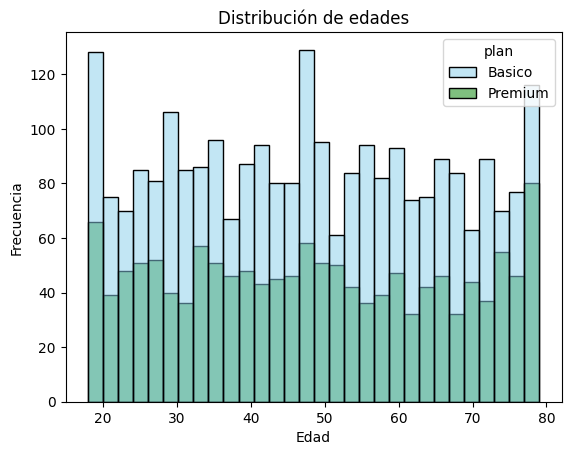

In [187]:
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    bins=30,
    palette=['skyblue', 'green']
)
# Histograma para visualizar la edad (age)

plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Distribución de edades')
plt.show()


💡Insights: 
Distribución de edades: Los datos abarcan aproximadamente desde los 18 hasta los 80 años.
La distribución es bastante uniforme, sin una concentración marcada en un rango específico.
Se observan algunos picos de frecuencia alrededor de los 18, 48 y 79 años.
No parece existir un sesgo fuerte hacia personas jóvenes o mayores.
Esto sugiere una muestra con representación relativamente amplia de diferentes grupos de edad.

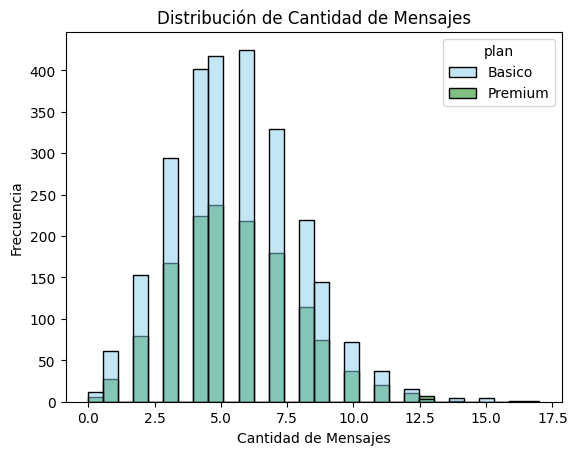

In [188]:
# Histograma para visualizar la cant_mensajes

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    bins=30,
    palette=['skyblue', 'green']
)

plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')
plt.title('Distribución de Cantidad de Mensajes')
plt.show()


💡Insights: 
La distribución se concentra principalmente entre 3 y 8 mensajes.
El punto de mayor frecuencia está alrededor de 4–6 mensajes, especialmente cerca de 5 mensajes.
La cantidad de mensajes presenta una distribución con sesgo hacia la derecha, ya que existen algunos usuarios con cantidades mucho mayores de mensajes.
La mayoría de los registros tienen menos de 10 mensajes.
A partir de aproximadamente 10 mensajes, la frecuencia disminuye considerablemente.
Hay algunos casos extremos de 12–17 mensajes, que podrían considerarse valores poco frecuentes.
En general, el comportamiento típico parece estar alrededor de 5–6 mensajes por usuario/registro.

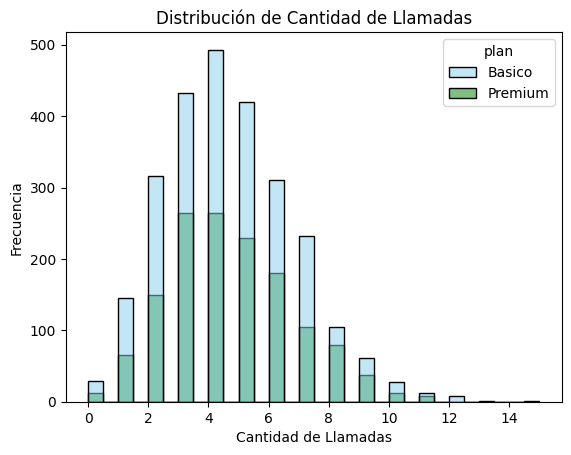

In [189]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    bins=30,
    palette=['skyblue', 'green']
)

plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Frecuencia')
plt.title('Distribución de Cantidad de Llamadas')
plt.show()


💡Insights: 
-La cantidad de llamadas se concentra principalmente entre 3 y 7 llamadas, con la mayor frecuencia alrededor de 4 a 6 llamadas. La distribución presenta un ligero sesgo hacia la derecha, debido a que algunos usuarios registran una cantidad de llamadas considerablemente mayor. La mayoría de los registros tiene menos de 8 llamadas, mientras que los valores entre 12 y 14 llamadas son poco frecuentes y podrían considerarse posibles valores extremos. En general, el comportamiento típico se encuentra entre 3 y 7 llamadas.

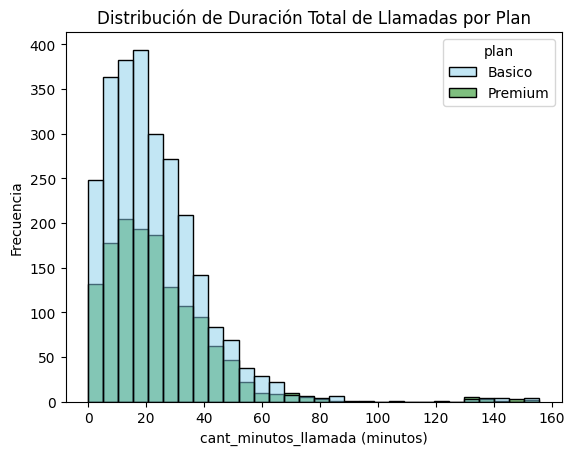

In [190]:
# Histograma para visualizar la cant_minutos_llamada


sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    bins=30,
    palette=['skyblue', 'green']

)

plt.xlabel('cant_minutos_llamada (minutos)')
plt.ylabel('Frecuencia')
plt.title('Distribución de Duración Total de Llamadas por Plan')
plt.show()

💡Insights: 
La duración total de las llamadas presenta una distribución sesgada a la derecha en ambos planes: la mayoría de las llamadas duran pocos minutos y hay pocas llamadas muy largas.
El Plan Básico concentra la mayor frecuencia de llamadas, especialmente entre 10 y 30 minutos.
El Plan Premium también se concentra en duraciones cortas, aunque presenta una distribución algo más extendida.
Existen llamadas excepcionalmente largas en ambos planes, con algunos casos que superan los 100 minutos.
En general, no se observa una diferencia radical en el patrón de duración entre Básico y Premium; ambos muestran un comportamiento similar, con mayor concentración en llamadas relativamente cortas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

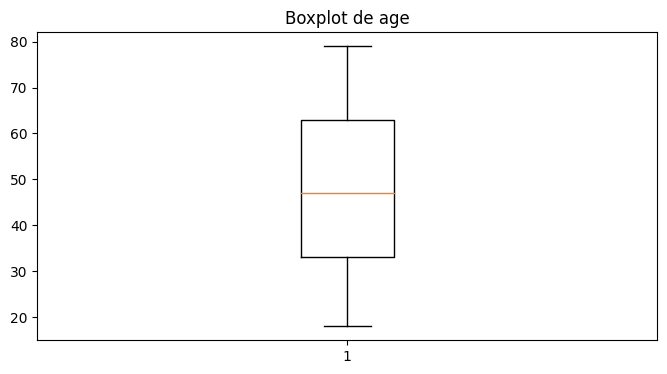

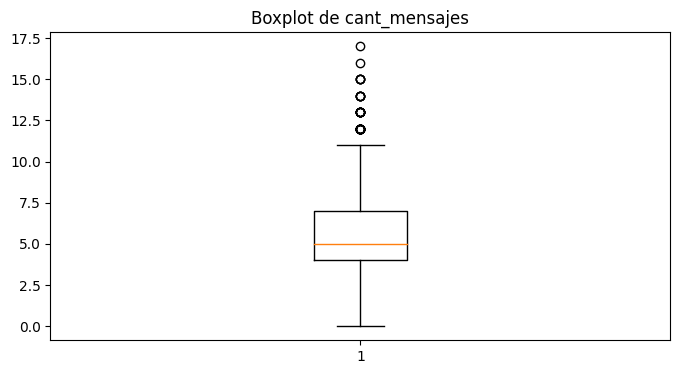

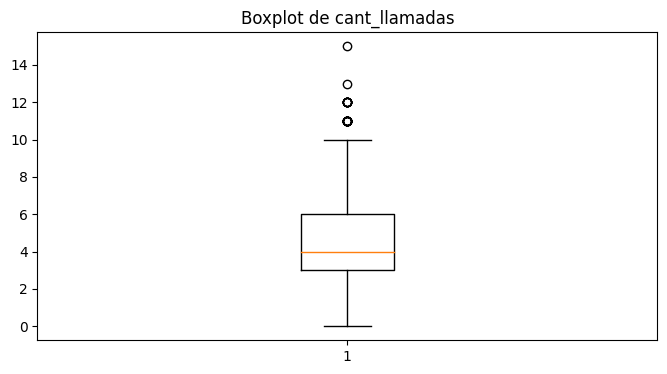

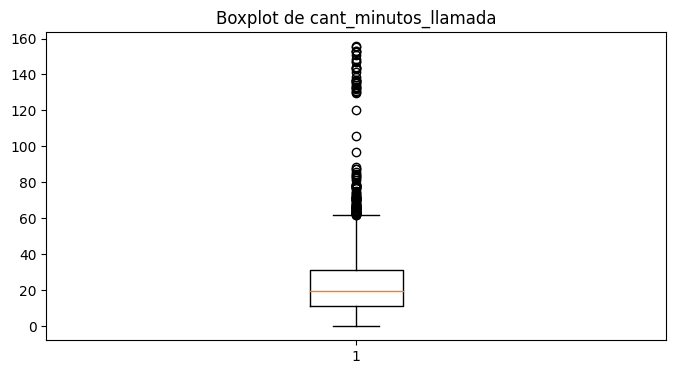

In [191]:

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:

    plt.figure(figsize=(8, 4))

    plt.boxplot(user_profile[col].dropna())

    plt.title(f'Boxplot de {col}')

    plt.show()


💡Insights: 
* Age: No presenta valores atípicos visibles. Los datos se encuentran aproximadamente entre 18 y 79 años y no se observan puntos fuera de los bigotes. Por lo tanto, no parece necesario realizar una limpieza de outliers en esta variable.
* cant_mensajes: Presenta varios valores atípicos por encima del límite superior. La mayoría de los usuarios se concentra aproximadamente entre 4 y 7 mensajes, mientras que algunos usuarios registran cantidades mayores. Estos valores deben revisarse antes de decidir si se eliminan.
* cant_llamadas: Presenta varios valores atípicos por encima del límite superior. La mayor concentración se encuentra aproximadamente entre 3 y 6 llamadas, mientras que algunos usuarios superan las 10 llamadas. Se recomienda revisar estos casos antes de eliminarlos.
* cant_minutos_llamada: Presenta numerosos valores atípicos por encima del límite superior. La mayoría de los valores se concentra aproximadamente entre 10 y 30 minutos, pero existen usuarios con duraciones considerablemente mayores. Estos valores podrían representar un consumo real elevado, por lo que se recomienda revisarlos antes de realizar una limpieza.

* Conclusión general: age no presenta outliers visibles, mientras que las tres variables relacionadas con el uso (cant_mensajes, cant_llamadas y cant_minutos_llamada) sí presentan valores extremos. Estos no deberían eliminarse automáticamente, ya que podrían representar usuarios con un uso elevado y real del servicio.

In [192]:

# Calcular límites con el método IQR

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    maximo = user_profile[col].max()


   
    print(f'\nColumna: {col}')
    print(f'Límite Superior: {limite_sup:.2f}')
    print(f'Máximo: {maximo:.2f}')




Columna: age
Límite Superior: 108.00
Máximo: 79.00

Columna: cant_mensajes
Límite Superior: 11.50
Máximo: 17.00

Columna: cant_llamadas
Límite Superior: 10.50
Máximo: 15.00

Columna: cant_minutos_llamada
Límite Superior: 61.86
Máximo: 155.69


In [200]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
print(f'\nColumna: {col}')
print(f'Límite Superior: {limite_sup:.2f}')
print(f'Máximo: {maximo:.2f}')



Columna: cant_minutos_llamada
Límite Superior: 61.86
Máximo: 155.69


💡Insights: 
- cant_mensajes: mantener los outliers, siempre que representen usuarios reales. Una cantidad muy alta de mensajes puede corresponder a usuarios con un uso intensivo del servicio y no necesariamente a errores en los datos.
- cant_llamadas:mantener los outliers, porque algunos usuarios pueden realizar muchas más llamadas que el promedio. Estos valores pueden ser importantes para analizar el comportamiento de los usuarios y el consumo del servicio.
- cant_minutos_llamada: mantener los outliers, porque aunque el límite superior es 61.86 minutos y existe un máximo de 155.69 minutos, una llamada muy larga puede ser un comportamiento real y no necesariamente un dato erróneo. Eliminarla podría hacer que perdiéramos información sobre usuarios con un uso excepcionalmente alto.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [194]:



# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

valores = [
    'Bajo uso',
    'Uso medio'
]

user_profile['grupo_uso'] = np.select(
    condiciones,
    valores,
    default='Alto uso'
)





In [195]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [196]:
# Crear columna grupo_edad

condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

valores = [
    'Joven',
    'Adulto'
]

user_profile['grupo_edad'] = np.select(
    condiciones,
    valores,
    default='Adulto Mayor'
)



In [197]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

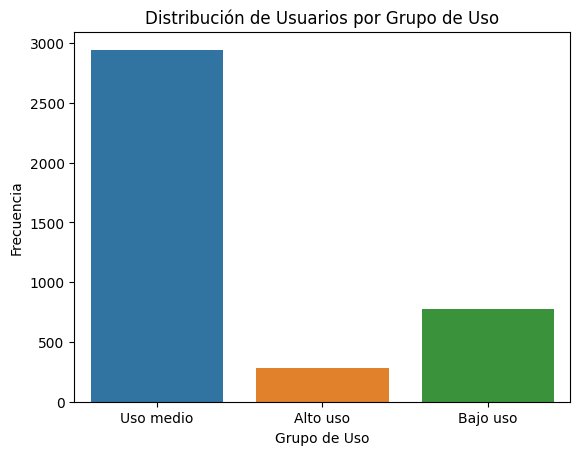

In [198]:

# Visualización de los segmentos por uso

sns.countplot(x='grupo_uso', data=user_profile)
plt.xlabel('Grupo de Uso')
plt.ylabel('Frecuencia')
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.show()

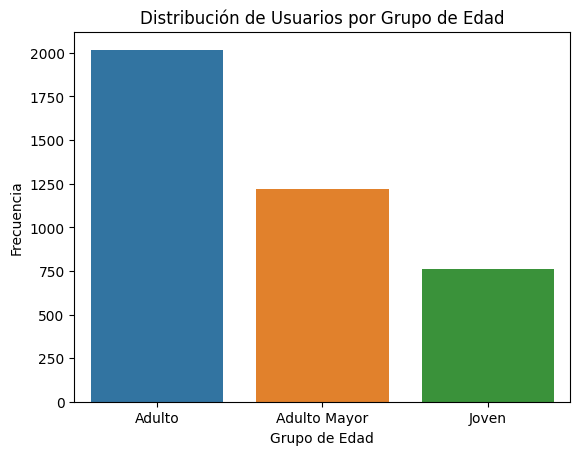

In [199]:
# Visualización de los segmentos por edad
sns.countplot(x='grupo_edad', data=user_profile)
plt.xlabel('Grupo de Edad')
plt.ylabel('Frecuencia')
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

Esto sugiere que ConnectaTel tiene una base de clientes heterogénea: existen usuarios de bajo consumo que podrían requerir planes más económicos y usuarios de alto consumo que representan una oportunidad para planes con mayores beneficios. La distribución por plan no muestra diferencias radicales en el comportamiento de llamadas, por lo que sería conveniente complementar esta segmentación con información de rentabilidad y consumo de cada plan.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Se encontraron valores faltantes principalmente en city y churn_date. En city había 469 registros nulos de 4,000 usuarios (11.725%), mientras que churn_date tenía 3,534 nulos (88.35%). En este último caso, los nulos pueden representar usuarios que todavía no han abandonado el servicio, por lo que no se recomienda eliminarlos.
También se detectó el valor -999 en age, que es un valor inválido para una edad y funcionaba como sentinel. Se reemplazó por la mediana. En city también se identificó un valor "?", que fue tratado como dato nulo.
En usage había valores faltantes en duration (22,076 de 40,000 registros) y length (17,896 de 40,000 registros). Estos faltantes están relacionados con el tipo de registro: duration corresponde principalmente a llamadas y length a mensajes, por lo que no deben interpretarse automáticamente como errores.
También se encontraron 50 fechas faltantes en usage.date, equivalentes al 0.125% de los registros.


🔍 **Segmentos por Edad**
Se identificaron tres grupos: Joven (<30 años), Adulto (30 a <60 años) y Adulto Mayor (60 años o más).
La edad de los usuarios se encuentra aproximadamente entre 18 y 79 años y la distribución es bastante uniforme, sin una concentración marcada en un único grupo. Por lo tanto, ConnectaTel atiende a una base de clientes relativamente diversa en términos de edad. 


📊 **Segmentos por Nivel de Uso**
Se clasificaron los usuarios en Bajo uso, Uso medio y Alto uso, utilizando la cantidad de llamadas y mensajes como criterios. Los usuarios de bajo uso realizan menos de 5 llamadas y menos de 5 mensajes; los de uso medio realizan menos de 10 llamadas y menos de 10 mensajes; el resto se considera de alto uso.
Las variables de uso presentan una distribución sesgada hacia la derecha. La mayoría de los usuarios tiene un consumo relativamente bajo, mientras que existe un grupo menor de usuarios con un nivel de uso considerablemente mayor.

➡️ Esto sugiere que ConnectaTel tiene una base de clientes heterogénea: existen usuarios de bajo consumo que podrían requerir planes más económicos y usuarios de alto consumo que representan una oportunidad para planes con mayores beneficios. La distribución por plan no muestra diferencias radicales en el comportamiento de llamadas, por lo que sería conveniente complementar esta segmentación con información de rentabilidad y consumo de cada plan.


💡 **Recomendaciones**
Mantener y monitorear los outliers de uso en lugar de eliminarlos automáticamente. Se detectaron valores superiores a los límites del IQR: cant_mensajes alcanza 17, cant_llamadas alcanza 15 y cant_minutos_llamada alcanza 155.69 minutos, frente a un límite superior de 61.86 minutos. Estos valores pueden representar clientes reales con consumo intensivo y constituyen una oportunidad comercial.
Considerar una estrategia de segmentación de planes por nivel de consumo: un plan básico para usuarios de bajo uso, un plan intermedio para usuarios de consumo medio y una opción con mayores beneficios para usuarios de alto consumo.
Para los usuarios de alto uso, se podrían ofrecer planes Premium o paquetes adicionales de minutos y mensajes, buscando aumentar el valor generado por cliente y evitar que estos usuarios tengan que contratar servicios externos por falta de capacidad.
Para los usuarios de bajo uso, sería conveniente evaluar planes más económicos o flexibles que se ajusten mejor a su consumo, lo que podría mejorar la percepción de valor y reducir el riesgo de abandono.
Utilizar churn_date para analizar la permanencia y diseñar estrategias de retención, ya que el 88.35% de sus valores son nulos y probablemente corresponden a clientes que aún permanecen activos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`